## Import Dependencies

In [1]:
# import system libs
import os, glob
import time
import shutil
import pathlib
import itertools
from PIL import Image

# import data handling tools
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# import Deep learning Libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam, Adamax
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras import regularizers

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

print ('modules loaded')

modules loaded


In [2]:
import sys, torch
print(sys.version)
print(torch.__version__, torch.version.cuda, torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")
print("TensorFlow version:", tf.__version__)

print("Available GPUs:", tf.config.list_physical_devices('GPU'))
!nvidia-smi

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
2.14.1+cpu None False
no GPU
TensorFlow version: 2.21.0
Available GPUs: []
/bin/bash: line 1: nvidia-smi: command not found


# Data Management

In [3]:
import kagglehub

# Download latest version
BASE_DIR = kagglehub.dataset_download("briscdataset/brisc2025")
SEED = 123
print("Path to dataset files:", BASE_DIR)

Using Colab cache for faster access to the 'brisc2025' dataset.
Path to dataset files: /kaggle/input/brisc2025


In [4]:
def walk_dir(base, max_depth=2):
    for root, dirs, _ in os.walk(base):
        depth = root.replace(base, "").count(os.sep)
        if depth <= max_depth:
            indent = "  " * depth
            print(f"{indent}{os.path.basename(root)}/")
            for d in dirs:
                print(f"{indent}  {d}/")

## Data Tree

In [5]:
print("\n## BRISC2025 Folder Layout:")
walk_dir(BASE_DIR, max_depth=3)


## BRISC2025 Folder Layout:
brisc2025/
  brisc2025/
  brisc2025/
    segmentation_task/
    classification_task/
    segmentation_task/
      test/
      train/
      test/
        images/
        masks/
      train/
        images/
        masks/
    classification_task/
      test/
      train/
      test/
        pituitary/
        no_tumor/
        meningioma/
        glioma/
      train/
        pituitary/
        no_tumor/
        meningioma/
        glioma/


In [6]:
# Generate data paths with labels
filepaths = []
labels = []

folds = os.listdir(BASE_DIR)
for fold in folds:
    foldpath = os.path.join(BASE_DIR, fold)
    filelist = os.listdir(foldpath)
    for file in filelist:
        fpath = os.path.join(foldpath, file)

        filepaths.append(fpath)
        labels.append(fold)

# Concatenate data paths with labels into one dataframe
Fseries = pd.Series(filepaths, name= 'filepaths')
Lseries = pd.Series(labels, name='labels')
df = pd.concat([Fseries, Lseries], axis= 1)

##  Parse the Classification Task Dataset

In [7]:
# Define the base directory for classification train
classification_train_dir = os.path.join(BASE_DIR, "brisc2025", "classification_task", "train")

filepaths = []
labels = []

# Check if directory exists
if os.path.exists(classification_train_dir):
    # Iterate through each class folder (glioma, pituitary, meningioma, no_tumor)
    classes = os.listdir(classification_train_dir)
    for class_name in classes:
        class_dir = os.path.join(classification_train_dir, class_name)
        if os.path.isdir(class_dir):
            for file in os.listdir(class_dir):
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    filepaths.append(os.path.join(class_dir, file))
                    labels.append(class_name)

# Create classification dataframe
classification_df = pd.DataFrame({
    'filepaths': filepaths,
    'labels': labels
})

print(f"Loaded {len(classification_df)} training images for Classification Task.")
display(classification_df.head())
print("\nClass distributions:\n", classification_df['labels'].value_counts())

Loaded 5000 training images for Classification Task.


,filepaths,labels
0,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
1,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
2,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
3,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
4,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary



Class distributions:
 labels
pituitary     1457
meningioma    1329
glioma        1147
no_tumor      1067
Name: count, dtype: int64


In [8]:
print("Mutliclass TRAIN / EVAL DATASET")
print("_____________________________________________________")
print("_____________________________________________________")

classification_df

Mutliclass TRAIN / EVAL DATASET
_____________________________________________________
_____________________________________________________


,filepaths,labels
0,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
1,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
2,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
3,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
4,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
...,...,...
4995,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
4996,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
4997,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
4998,/kaggle/input/brisc2025/brisc2025/classificati...,glioma


### Parse the Test Set (Classification Task)

In [9]:
# Define the base directory for classification test
classification_test_dir = os.path.join(BASE_DIR, "brisc2025", "classification_task", "test")

test_filepaths = []
test_labels = []

if os.path.exists(classification_test_dir):
    classes = os.listdir(classification_test_dir)
    for class_name in classes:
        class_dir = os.path.join(classification_test_dir, class_name)
        if os.path.isdir(class_dir):
            for file in os.listdir(class_dir):
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    test_filepaths.append(os.path.join(class_dir, file))
                    test_labels.append(class_name)

# Create classification test dataframe
classification_test_df = pd.DataFrame({
    'filepaths': test_filepaths,
    'labels': test_labels
})

print(f"Loaded {len(classification_test_df)} test images for Classification Task.")
display(classification_test_df.head())
print("\nTest Class distributions:\n", classification_test_df['labels'].value_counts())

Loaded 1000 test images for Classification Task.


,filepaths,labels
0,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
1,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
2,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
3,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
4,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary



Test Class distributions:
 labels
meningioma    306
pituitary     300
glioma        254
no_tumor      140
Name: count, dtype: int64


In [10]:
print("Multiclass TEST DATASET")
print("_____________________________________________________")
print("_____________________________________________________")

classification_test_df

Multiclass TEST DATASET
_____________________________________________________
_____________________________________________________


,filepaths,labels
0,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
1,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
2,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
3,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
4,/kaggle/input/brisc2025/brisc2025/classificati...,pituitary
...,...,...
995,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
996,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
997,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
998,/kaggle/input/brisc2025/brisc2025/classificati...,glioma


## Make Binary YES = 1 / NO = 0 Tumor Data

We will make the YES = 1 / NO = 0 binary tumor classfier with an equal split of the no_tumor and tumor labels, balancing the number of each type of tumor. Since there are 1067 no_tumor images, we will use 355 meningioma, 356 pituitary, and 356 glioma images. We will use the same seed as our reference project @abdallahwagih in Kaggle, to compare our results using the larger BRISC dataset that was verified and corrected by medical physicians.  

In [11]:
# Keep all the no_tumor images
BINARY_no_tumor = classification_df[classification_df['labels'] == 'no_tumor'].copy()

# Sample desired subsets of each tumor class
BINARY_meningioma = classification_df[classification_df['labels'] == 'meningioma'].sample(n=355, random_state=SEED)
BINARY_pituitary = classification_df[classification_df['labels'] == 'pituitary'].sample(n=356, random_state=SEED)
BINARY_glioma = classification_df[classification_df['labels'] == 'glioma'].sample(n=356, random_state=SEED)

# Combine samples
binary_df = pd.concat([
    BINARY_no_tumor, BINARY_meningioma, BINARY_pituitary, BINARY_glioma
])

# Change tumor labels to YES = 1 and no_tumor to NO = 0
binary_df['labels'] = binary_df['labels'].replace({
    'meningioma': '1',
    'pituitary': '1',
    'glioma': '1',
    'no_tumor': '0'
})

# Stratify data into train using sklearn.model_selection
strat = binary_df['labels']
train_df, eval_df = train_test_split(binary_df,  train_size= 0.8, shuffle= True, random_state= SEED, stratify= strat)

# Make binary test labels // .isin() makes boolean arr // astype maps to 1 / 0
test_df = classification_test_df.copy()

test_df['labels'] = test_df['labels'].isin(
    ['meningioma', 'pituitary', 'glioma']).astype(int).astype(str)


# Print new data distribution
print("_____________________________________________________")
print("BINARY TRAIN / EVAL DATASET")
print("_____________________________________________________")
print(binary_df['labels'].value_counts())
print()
print()
print("_____________________________________________________")
print()
print("BINARY TEST DATASET")
print("_____________________________________________________")
print(test_df['labels'].value_counts())

_____________________________________________________
BINARY TRAIN / EVAL DATASET
_____________________________________________________
labels
0    1067
1    1067
Name: count, dtype: int64


_____________________________________________________

BINARY TEST DATASET
_____________________________________________________
labels
1    860
0    140
Name: count, dtype: int64


In [12]:
binary_df

,filepaths,labels
1457,/kaggle/input/brisc2025/brisc2025/classificati...,0
1458,/kaggle/input/brisc2025/brisc2025/classificati...,0
1459,/kaggle/input/brisc2025/brisc2025/classificati...,0
1460,/kaggle/input/brisc2025/brisc2025/classificati...,0
1461,/kaggle/input/brisc2025/brisc2025/classificati...,0
...,...,...
4168,/kaggle/input/brisc2025/brisc2025/classificati...,1
4887,/kaggle/input/brisc2025/brisc2025/classificati...,1
4474,/kaggle/input/brisc2025/brisc2025/classificati...,1
4780,/kaggle/input/brisc2025/brisc2025/classificati...,1


## Load / Preprocess Data

In [13]:
batch_size = 8
img_size = (224, 224)
channels = 3

# input channel dim last in tensorflow
img_shape = (img_size[0], img_size[1], channels)

tr_gen = ImageDataGenerator()
ts_gen = ImageDataGenerator()

train_gen = tr_gen.flow_from_dataframe(
    train_df, x_col= 'filepaths',
    y_col= 'labels',
    target_size= img_size,
    class_mode= 'binary',
    color_mode= 'rgb', shuffle= True, batch_size= batch_size)

eval_gen = ts_gen.flow_from_dataframe(
    eval_df,
    x_col= 'filepaths',
    y_col= 'labels',
    target_size= img_size,
    class_mode= 'binary',
    color_mode= 'rgb', shuffle= False, batch_size= batch_size)

test_gen = ts_gen.flow_from_dataframe(
    test_df,
    x_col='filepaths',
    y_col='labels',
    target_size=img_size,
    class_mode='binary',
    color_mode='rgb',shuffle=False,batch_size=batch_size
)

Found 1707 validated image filenames belonging to 2 classes.
Found 427 validated image filenames belonging to 2 classes.
Found 1000 validated image filenames belonging to 2 classes.


## Model

In [14]:
# entire layer is being fine tuned trainable = True
efficientnet_backbone = tf.keras.applications.efficientnet.EfficientNetB3(
    include_top= False, weights= "imagenet",
    input_shape= img_shape, pooling= 'max')

# Unfreeze only the last 10 layers for a fine-tuning speedup
efficientnet_backbone.trainable = True
for layer in efficientnet_backbone.layers[:-10]:
    layer.trainable = False

# Keep all BatchNormalization layers frozen
for layer in efficientnet_backbone.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Build model
inputs = tf.keras.Input(shape=img_shape)

# dropout set to 0, batch norm uses running mean/var (not moving)
# does not affect backprogation determined by layer.trainable=True
x = efficientnet_backbone(inputs, training=False)

x = BatchNormalization()(x)

x = Dense(
    256,
    activation='relu',
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = Dropout(0.45)(x)

outputs = Dense(1, activation='sigmoid')(x)

model = tf.keras.Model(inputs, outputs)

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adamax(
        learning_rate=1e-5
    ),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb3 (Functional)     │ (None, 1536)           │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1536)           │         6,144 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       393,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,183,408 (42.66 MB)

 Trainable params: 2,094,849 (7.99 MB)

 Non-trainable params: 9,088,559 (34.67 MB)

## Check shapes

In [15]:
print("Training samples:", train_gen.samples)
print("Validation samples:", eval_gen.samples)
print("Test samples:", test_gen.samples)

print("Class mapping:", train_gen.class_indices)

images, labels = next(iter(train_gen))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Unique labels:", np.unique(labels))

Training samples: 1707
Validation samples: 427
Test samples: 1000
Class mapping: {'0': 0, '1': 1}
Image batch shape: (8, 224, 224, 3)
Label batch shape: (8,)
Unique labels: [0. 1.]


## Configure Checkpoints

In [16]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Create a directory in your Google Drive for checkpoints
checkpoint_dir = '/content/drive/MyDrive/brain_tumor_checkpoints'
os.makedirs(checkpoint_dir, exist_ok=True)
checkpoint_path = os.path.join(checkpoint_dir, 'kaggle_reference_redo.keras')

print(f"Checkpoints will be saved to: {checkpoint_path}")

# Define the ModelCheckpoint callback
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

# Create a separate directory for training recovery
backup_dir = os.path.join(
    checkpoint_dir,
    'training_recovery'
)

os.makedirs(backup_dir, exist_ok=True)

# Configure automatic recovery
backup_callback = tf.keras.callbacks.BackupAndRestore(
    backup_dir=backup_dir,
    save_freq='epoch',
    delete_checkpoint=True
)

csv_logger = tf.keras.callbacks.CSVLogger(
    filename=os.path.join(
        checkpoint_dir,
        'training_history.csv'
    ),
    append=True
)

# allows my training to stop after 5 consecutive epochs w/o val loss improve
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# reduces learning rate when training hits a plateau
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

print("ModelCheckpoint, EarlyStop, and  callback successfully configured.")

Mounted at /content/drive
Checkpoints will be saved to: /content/drive/MyDrive/brain_tumor_checkpoints/kaggle_reference_redo.keras
ModelCheckpoint, EarlyStop, and  callback successfully configured.


In [ ]:
history = model.fit(
    x=train_gen,
    epochs=30,
    verbose=1,
    validation_data=eval_gen,
    validation_steps=None,
    shuffle=False,
    callbacks=[checkpoint_callback, early_stopping, reduce_lr]
)

Epoch 1/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9566 - loss: 0.1604
Epoch 1: val_loss improved from 0.10820 to 0.10816, saving model to /content/drive/MyDrive/brain_tumor_checkpoints/kaggle_reference_redo.keras

Epoch 1: finished saving model to /content/drive/MyDrive/brain_tumor_checkpoints/kaggle_reference_redo.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 372s 2s/step - accuracy: 0.9502 - loss: 0.1767 - val_accuracy: 0.9766 - val_loss: 0.1082 - learning_rate: 1.0000e-05
Epoch 2/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9506 - loss: 0.1798
Epoch 2: val_loss improved from 0.10816 to 0.10669, saving model to /content/drive/MyDrive/brain_tumor_checkpoints/kaggle_reference_redo.keras

Epoch 2: finished saving model to /content/drive/MyDrive/brain_tumor_checkpoints/kaggle_reference_redo.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 359s 2s/step - accuracy: 0.9508 - loss: 0.1751 - val_accuracy: 0.9789 - val_loss: 0.1067 - learning_rate: 1.0000e-05
Epoch 3/30
214/214 ━━━━━━━━━━━━━

In [ ]:
history = model.fit(
    x=train_gen,
    epochs=30,
    verbose=1,
    validation_data=eval_gen,
    validation_steps=None,
    shuffle=False,
    callbacks=[checkpoint_callback, early_stopping, reduce_lr]
)

Epoch 1/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9566 - loss: 0.1604
Epoch 1: val_loss improved from 0.10820 to 0.10816, saving model to /content/drive/MyDrive/brain_tumor_checkpoints/kaggle_reference_redo.keras

Epoch 1: finished saving model to /content/drive/MyDrive/brain_tumor_checkpoints/kaggle_reference_redo.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 372s 2s/step - accuracy: 0.9502 - loss: 0.1767 - val_accuracy: 0.9766 - val_loss: 0.1082 - learning_rate: 1.0000e-05
Epoch 2/30
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9506 - loss: 0.1798
Epoch 2: val_loss improved from 0.10816 to 0.10669, saving model to /content/drive/MyDrive/brain_tumor_checkpoints/kaggle_reference_redo.keras

Epoch 2: finished saving model to /content/drive/MyDrive/brain_tumor_checkpoints/kaggle_reference_redo.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 359s 2s/step - accuracy: 0.9508 - loss: 0.1751 - val_accuracy: 0.9789 - val_loss: 0.1067 - learning_rate: 1.0000e-05
Epoch 3/30
214/214 ━━━━━━━━━━━━━

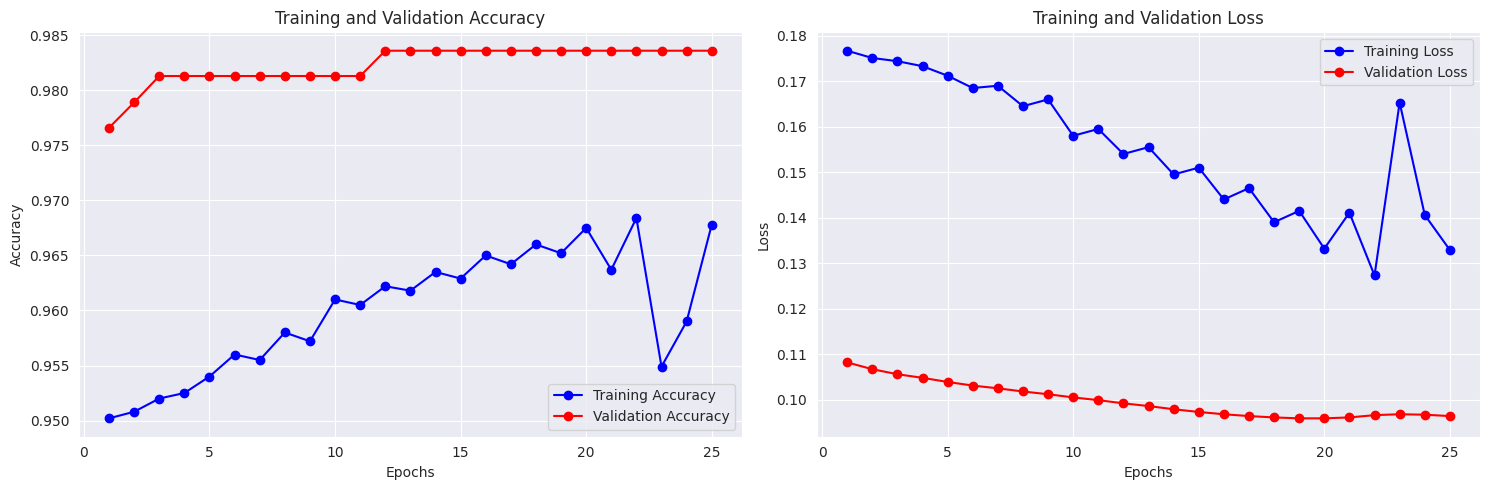

In [17]:
import matplotlib.pyplot as plt

# 1. Reconstruct the training history from the printed logs
# Extracting the metrics printed from the 25 epochs in your run
history_data = {
    'accuracy': [
        0.9502, 0.9508, 0.9520, 0.9525, 0.9540, 0.9560, 0.9555, 0.9580, 0.9572, 0.9610,
        0.9605, 0.9622, 0.9618, 0.9635, 0.9629, 0.9650, 0.9642, 0.9660, 0.9652, 0.9675,
        0.9637, 0.9684, 0.9549, 0.9590, 0.9678
    ],
    'loss': [
        0.1767, 0.1751, 0.1744, 0.1733, 0.1712, 0.1685, 0.1690, 0.1645, 0.1660, 0.1580,
        0.1595, 0.1540, 0.1555, 0.1495, 0.1510, 0.1440, 0.1465, 0.1390, 0.1415, 0.1332,
        0.1411, 0.1273, 0.1653, 0.1406, 0.1329
    ],
    'val_accuracy': [
        0.9766, 0.9789, 0.9813, 0.9813, 0.9813, 0.9813, 0.9813, 0.9813, 0.9813, 0.9813,
        0.9813, 0.9836, 0.9836, 0.9836, 0.9836, 0.9836, 0.9836, 0.9836, 0.9836, 0.9836,
        0.9836, 0.9836, 0.9836, 0.9836, 0.9836
    ],
    'val_loss': [
        0.1082, 0.1067, 0.1056, 0.1048, 0.1039, 0.1031, 0.1025, 0.1018, 0.1012, 0.1005,
        0.0999, 0.0992, 0.0986, 0.0979, 0.0973, 0.0968, 0.0964, 0.0961, 0.0959, 0.0959,
        0.0961, 0.0966, 0.0968, 0.0967, 0.0964
    ]
}

# 2. Plot Training & Validation Performance
epochs_range = range(1, len(history_data['accuracy']) + 1)

plt.figure(figsize=(15, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_data['accuracy'], 'bo-', label='Training Accuracy')
plt.plot(epochs_range, history_data['val_accuracy'], 'ro-', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_data['loss'], 'bo-', label='Training Loss')
plt.plot(epochs_range, history_data['val_loss'], 'ro-', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Loading the best saved model weights...
Model successfully loaded!
125/125 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step

Classification Report:
              precision    recall  f1-score   support

           0       0.71      1.00      0.83       140
           1       1.00      0.93      0.97       860

    accuracy                           0.94      1000
   macro avg       0.85      0.97      0.90      1000
weighted avg       0.96      0.94      0.95      1000



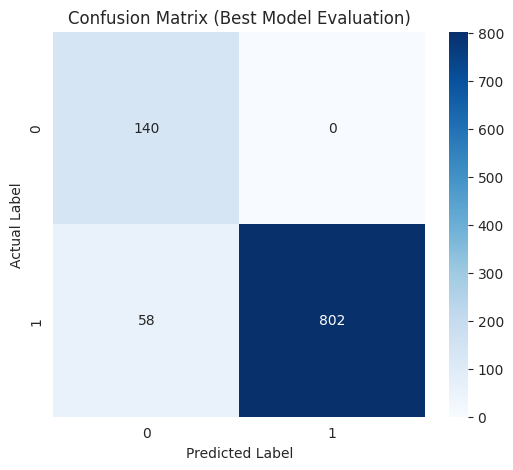

In [18]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Load the best saved model checkpoint
best_model_path = '/content/drive/MyDrive/brain_tumor_checkpoints/kaggle_reference_redo.keras'

print("Loading the best saved model weights...")
best_model = tf.keras.models.load_model(best_model_path)
print("Model successfully loaded!")

# 2. Generate predictions on the binary test dataset
predictions = best_model.predict(test_gen, verbose=1)

# Convert probabilities to binary predictions (using 0.5 threshold)
predicted_classes = (predictions > 0.5).astype(int).flatten()
true_classes = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

# 3. Print Classification Report
print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

# 4. Plot Confusion Matrix
cm = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix (Best Model Evaluation)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

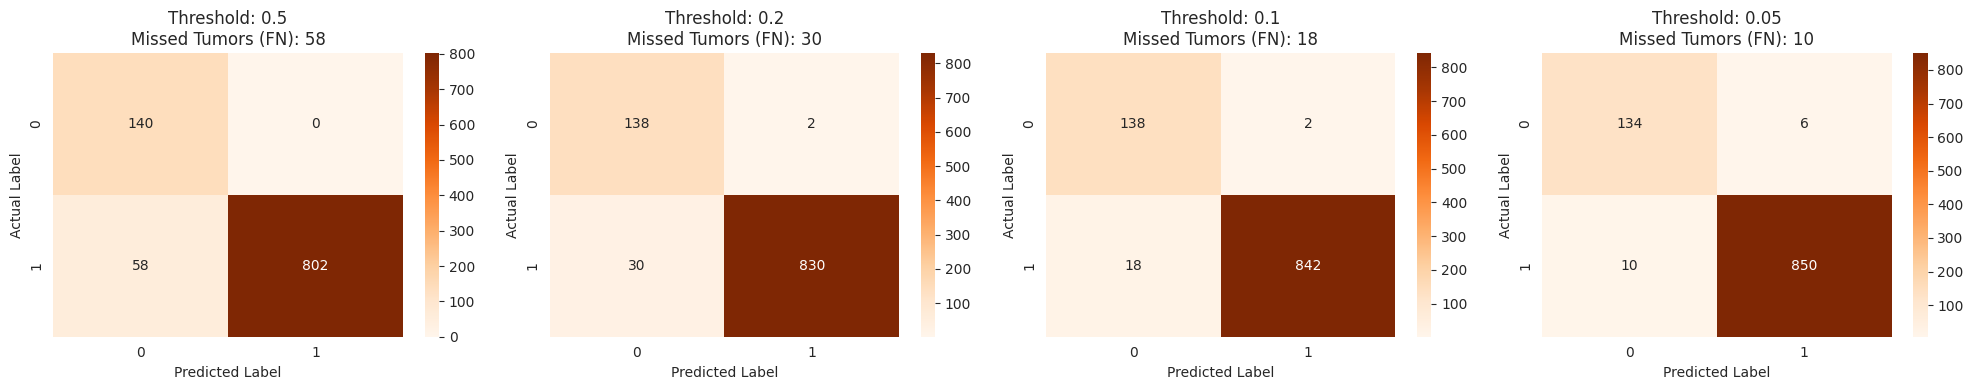


Updated Classification Report with Highly Sensitive Threshold (0.1):
              precision    recall  f1-score   support

           0       0.88      0.99      0.93       140
           1       1.00      0.98      0.99       860

    accuracy                           0.98      1000
   macro avg       0.94      0.98      0.96      1000
weighted avg       0.98      0.98      0.98      1000



In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Let's explore multiple thresholds to see how they impact False Negatives (Missed Tumors)
thresholds = [0.5, 0.2, 0.1, 0.05]

plt.figure(figsize=(20, 4))

for i, thresh in enumerate(thresholds):
    # Apply the custom threshold
    custom_predicted_classes = (predictions > thresh).astype(int).flatten()

    # Generate confusion matrix
    cm_custom = confusion_matrix(true_classes, custom_predicted_classes)

    # Plot confusion matrix
    plt.subplot(1, 4, i + 1)
    sns.heatmap(cm_custom, annot=True, fmt='d', cmap='Oranges',
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title(f'Threshold: {thresh}\nMissed Tumors (FN): {cm_custom[1, 0]}')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')

plt.tight_layout()
plt.show()

# Let's choose 0.1 as our new operating threshold and print the updated report
chosen_threshold = 0.1
final_predictions = (predictions > chosen_threshold).astype(int).flatten()

print(f"\nUpdated Classification Report with Highly Sensitive Threshold ({chosen_threshold}):")
print(classification_report(true_classes, final_predictions, target_names=class_labels))